# code_048 · Duplicates, identities and inconsistent records

**Book:** section 10.2. A self-contained data-cleaning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_10_GUIDE.md), [run evidence](../CHAPTER_10_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_048).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All data and calibration/measurement assumptions are simulated, without field safety, causal or universal cleaning claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1048;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1048


<a id="identity"></a>
## An identical value is not an event identity

Two buildings both contain local member 7. Four inspection events use stable event IDs. Two legitimate inspections of building A/member 7 occur on different days with the same grade. One event is reimported twice unchanged; another has an updated grade in a new revision. Raw import rows are evidence about events and versions, not independent learning cases. Keep building+local-member identity, event ID, revision, arrival and import-row ID.

A normalized-name match can propose candidate links but must not merge entities merely because local member numbers agree. This is a construction/provenance audit, without a fitted predictor or empirical entity-resolution accuracy claim.


In [2]:
cols=['import_id','building_id','local_member','event_id','event_day','revision','arrival_day','grade']
raw=pd.DataFrame([('r1','A',7,'e1',1,1,2,2),('r2','A',7,'e1',1,1,2,2),('r3','A',7,'e2',8,1,9,2),('r4','B',7,'e3',2,1,3,1),('r5','A',8,'e4',3,1,4,1),('r6','A',8,'e4',3,2,12,3),('r7','A',7,'e1',1,1,2,2)],columns=cols)
assert raw.import_id.is_unique and len(raw)==7
entities=raw[['building_id','local_member']].drop_duplicates();assert len(entities)==3 and raw.local_member.nunique()==2
key=['event_id','revision'];payload=[c for c in cols if c!='import_id']
assert raw[raw.event_id=='e1'][payload].drop_duplicates().shape[0]==1
versions=raw.drop_duplicates(key,keep='first').copy();lineage=raw.groupby(key).import_id.agg(list).to_dict()
assert len(versions)==5 and len(lineage[('e1',1)])==3
assert versions[versions.event_id.isin(['e1','e2'])].grade.nunique()==1
RESULTS.update({'raw_import_rows':7,'unique_event_versions':5,'stable_entities':3,'events':int(raw.event_id.nunique()),'e1_import_lineage':lineage[('e1',1)]})


<a id="conflicts"></a>
## Reject conflicting payloads before picking a survivor

Deduplicating by key is valid only after confirming payload equivalence under the source contract. A fabricated second e2/revision1 row with a different grade is a conflict, not a harmless duplicate. Resolve it through adjudication or an authoritative version sequence; never choose whichever import happened to sort first. For the actual unambiguous records, select only revisions arrived by cutoff day 10 or 15, then the latest known revision per event. The older event value remains reconstructable.


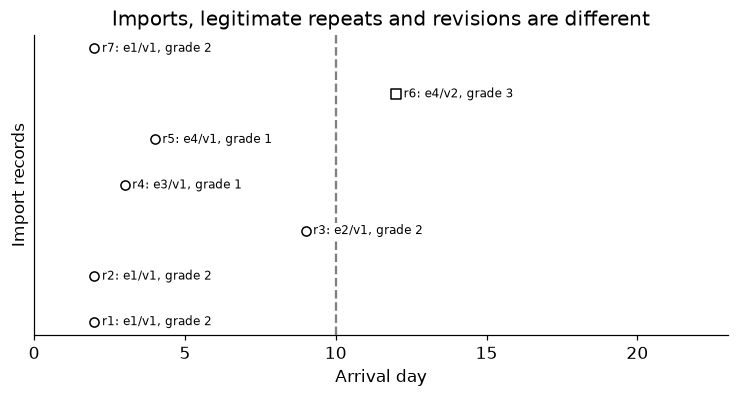

In [3]:
def check_payload(frame):
 for _,g in frame.groupby(key):
  if len(g[payload].drop_duplicates())>1:raise ValueError('Conflicting payload for event/revision')
check_payload(raw);conflict=raw.iloc[[2]].copy();conflict['import_id']='bad';conflict['grade']=4
caught=False
try:check_payload(pd.concat([raw,conflict],ignore_index=True))
except ValueError:caught=True
assert caught
def snapshot(cutoff):return versions[versions.arrival_day<=cutoff].sort_values(['event_id','revision']).drop_duplicates('event_id',keep='last').sort_values('event_id')
early=snapshot(10);late=snapshot(15);assert len(early)==len(late)==4
assert early.loc[early.event_id=='e4','grade'].iloc[0]==1 and late.loc[late.event_id=='e4','grade'].iloc[0]==3
assert set(early.event_id)=={'e1','e2','e3','e4'}
fig,ax=plt.subplots(figsize=(6.6,3.5))
for j,row in enumerate(raw.itertuples(index=False)):
 ax.scatter(row.arrival_day,j,marker='o' if row.revision==1 else 's',facecolors='white',edgecolors='black');ax.text(row.arrival_day+.25,j,f'{row.import_id}: {row.event_id}/v{row.revision}, grade {row.grade}',va='center',fontsize=8,bbox=dict(facecolor='white',edgecolor='none',pad=.4))
ax.axvline(10,color='.5',ls='--');ax.set(xlim=(0,23),yticks=[],xlabel='Arrival day',ylabel='Import records',title='Imports, legitimate repeats and revisions are different');plt.show()
RESULTS['conflicting_payload_rejected']=caught;RESULTS['e4_grade_by_cutoff']={'10':1,'15':3}


<a id="leakage"></a>
## Prevent copies of one event from crossing roles

A deliberately invalid alternating import-row split puts event e1 on both sides. Assigning unique events to roles after deduplication prevents this exact leakage, but does not guarantee building or temporal independence; those still follow the deployment contract. Keep the two legitimate same-grade inspections, because neither equal values nor shared member identity makes them the same event.


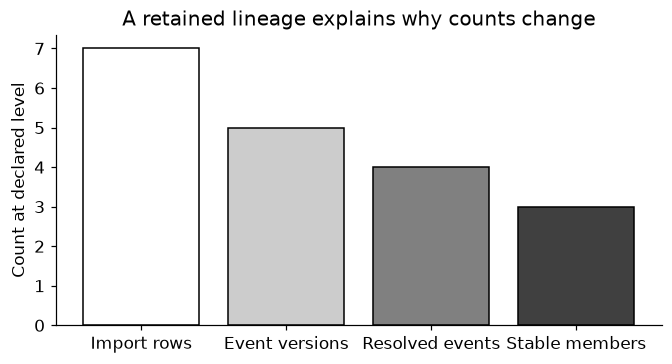

In [4]:
row_role=np.arange(len(raw))%2;overlap=set(raw.loc[row_role==0,'event_id'])&set(raw.loc[row_role==1,'event_id']);assert 'e1' in overlap
role={'e1':'train','e2':'development','e3':'final','e4':'train'}
resolved=late.copy();resolved['role']=resolved.event_id.map(role);assert resolved.event_id.is_unique
assert not set(resolved.loc[resolved.role=='train','event_id'])&set(resolved.loc[resolved.role=='final','event_id'])
assert {'e1','e2'}<=set(resolved.event_id) and len(resolved)==4
fig,ax=plt.subplots(figsize=(6,3.2));ax.bar(['Import rows','Event versions','Resolved events','Stable members'],[len(raw),len(versions),len(resolved),len(entities)],color=['white','.8','.5','.25'],edgecolor='black');ax.set(ylabel='Count at declared level',title='A retained lineage explains why counts change');plt.show()
RESULTS['invalid_import_split_overlapping_events']=sorted(overlap);RESULTS['resolved_event_count']=len(resolved);RESULTS['retained_same_grade_distinct_events']=['e1','e2']


<a id="exercises"></a>
## Exercises and hints

1. Add a near-duplicate with a rounded timestamp; identify candidates and leave ambiguous links for review.
2. Create two sources that reuse event IDs. Add source identity before matching.
3. Retain a tombstone/cancellation event and specify its historical availability.
4. Design building-grouped temporal roles instead of mistaking event separation for complete independence.

**Hints:** keys, payload equivalence, revision order and arrival are separate contracts. Keep discarded import IDs and the resolution reason. A string-similarity threshold is not a validated identity oracle. No probabilistic record-linkage model is claimed by this deterministic fixture.


In [5]:
summary={'example_id':'code_048','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['reimported records versus legitimate repeat events', 'composite entity identity', 'version conflicts and known-at-cutoff resolution', 'provenance retention during deduplication', 'duplicate event leakage across role assignments'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["reimported records versus legitimate repeat events", "composite entity identity", "version conflicts and known-at-cutoff resolution", "provenance retention during deduplication", "duplicate event leakage across role assignments"], "elapsed_seconds": 0.113, "example_id": "code_048", "hardware": "Darwin arm64 CPU", "results": {"conflicting_payload_rejected": true, "e1_import_lineage": ["r1", "r2", "r7"], "e4_grade_by_cutoff": {"10": 1, "15": 3}, "events": 4, "invalid_import_split_overlapping_events": ["e1", "e4"], "raw_import_rows": 7, "resolved_event_count": 4, "retained_same_grade_distinct_events": ["e1", "e2"], "stable_entities": 3, "unique_event_versions": 5}, "seed": 1048, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
